# UGP Project 1

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from tensorflow import keras
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.utils import set_random_seed

SEED = 67
set_random_seed(SEED)

CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

In [3]:
(X_all, y_all), (X_test, y_test) = fashion_mnist.load_data()

X_train, X_val, y_train, y_val = train_test_split(
    X_all, y_all,
    train_size=5000, test_size=5000,
    stratify=y_all, random_state=SEED,
)

def prepare(X):
    return X.reshape(len(X), 28 * 28).astype("float32") / 255.0

X_train, X_val, X_test = prepare(X_train), prepare(X_val), prepare(X_test)

print("Training:  ", X_train.shape, y_train.shape)  
print("Validation:", X_val.shape, y_val.shape)
print("Test:      ", X_test.shape, y_test.shape)
print("Images per class (training):", np.bincount(y_train, minlength=10))

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training:   (5000, 784) (5000,)
Validation: (5000, 784) (5000,)
Test:       (10000, 784) (10000,)
Images per class (training): [500 500 500 500 500 500 500 500 500 500]


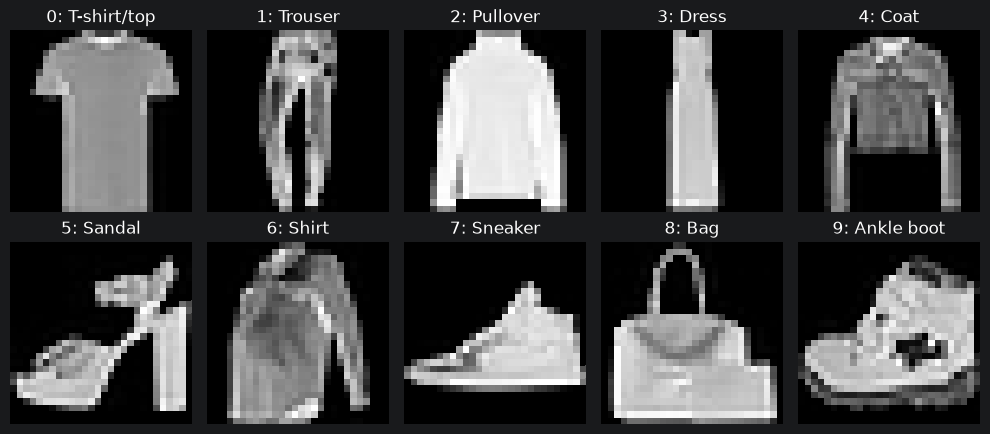

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for i, v in enumerate(axes.ravel()):
    index = np.where(y_train == i)[0][0]
    v.imshow(X_train[index].reshape(28, 28), cmap="gray")
    v.set_title(f"{i}: {CLASS_NAMES[i]}")
    v.axis("off")
plt.tight_layout()
plt.show()

In [5]:
from pathlib import Path
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)

def report(name, y_true, y_pred):
    print(f"{name}")
    print(f"  accuracy        = {accuracy_score(y_true, y_pred):.3f}")
    print(f"  macro precision = {precision_score(y_true, y_pred, average='macro', zero_division=0):.3f}")
    print(f"  macro recall    = {recall_score(y_true, y_pred, average='macro', zero_division=0):.3f}")
    print(f"  macro F1        = {f1_score(y_true, y_pred, average='macro', zero_division=0):.3f}")

most_common_class = np.bincount(y_train).argmax()
y_pred_dumb = np.full(len(y_val), most_common_class)

print("Always guessing class:", most_common_class, CLASS_NAMES[most_common_class])
report("Dumb baseline (validation)", y_val, y_pred_dumb)

Always guessing class: 0 T-shirt/top
Dumb baseline (validation)
  accuracy        = 0.100
  macro precision = 0.010
  macro recall    = 0.100
  macro F1        = 0.018


## Helpers

In [6]:
def build_mlp(hidden_units, dropout=0.0):
    """Build an MLP: 784 inputs -> hidden Dense layers (ReLU) -> 10 outputs (softmax)."""
    keras.backend.clear_session()
    set_random_seed(SEED)
    layers = [keras.Input(shape=(784,))]
    for layer_size in hidden_units:
        layers.append(keras.layers.Dense(layer_size, activation="relu"))
        if dropout > 0:
            layers.append(keras.layers.Dropout(dropout))
    layers.append(keras.layers.Dense(10, activation="softmax"))
    return keras.Sequential(layers)


def train(model, learning_rate=0.001, epochs=30, batch_size=64, optimizer=None, callbacks=None):
    """Compile and train the model. Returns the history (loss and accuracy per epoch)."""
    if optimizer is None:
        optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    model.compile(
        optimizer=optimizer,
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"],
    )
    return model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs, batch_size=batch_size,
        shuffle=True, callbacks=callbacks,
        verbose=2,
    )


def plot_history(history, title, filename):
    """Plot training vs validation loss and accuracy, and save the figure."""

    h = history.history
    epochs = range(1, len(h["loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    ax1.plot(epochs, h["loss"], label="Training")
    ax1.plot(epochs, h["val_loss"], label="Validation")
    ax1.set(xlabel="Epoch", ylabel="Loss (cross-entropy)", title="Loss")
    ax2.plot(epochs, h["accuracy"], label="Training")
    ax2.plot(epochs, h["val_accuracy"], label="Validation")
    ax2.set(xlabel="Epoch", ylabel="Accuracy", title="Accuracy")
    for ax in (ax1, ax2):
        ax.grid(alpha=0.3)
        ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    fig.savefig(RESULTS / filename, dpi=120)
    plt.show()


def predict_classes(model, X):
    return model.predict(X, verbose=0).argmax(axis=1)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
79/79 - 1s - 17ms/step - accuracy: 0.6836 - loss: 0.9420 - val_accuracy: 0.8042 - val_loss: 0.5985
Epoch 2/30
79/79 - 0s - 4ms/step - accuracy: 0.8048 - loss: 0.5847 - val_accuracy: 0.8274 - val_loss: 0.5207
Epoch 3/30
79/79 - 0s - 4ms/step - accuracy: 0.8294 - loss: 0.5118 - val_accuracy: 0.8352 - val_loss: 0.4876
Epoch 4/30
79/79 - 0s - 4ms/step - accuracy: 0.8394 - loss: 0.4677 - val_accuracy: 0.8448 - val_loss: 0.4657
Epoch 5/30
79/79 - 0s - 3ms/step - accuracy: 0.8544 - loss: 0.4348 - val_accuracy: 0.8480 - val_loss: 0.4548
Epoch 6/30
79/79 - 0s - 4ms/step - accuracy: 0.8618 - loss: 0.4074 - val_accuracy: 0.8514 - val_loss: 0.4482
Epoch 7/30
79/79 - 0s - 4ms/step - accuracy: 0.8690 - loss: 0.3844 - val_accuracy: 0.8506 - val_loss: 0.4404
Epoch 8/30
79/79 - 0s - 4ms/step - accuracy: 0.8730 - loss: 0.3643 - val_accuracy: 0.8524 - val_loss: 0.4352
Epoch 9/30
79/79 - 0s - 4ms/step - accuracy: 0.8812 - loss: 0.3440 - val_accuracy: 0.8552 - val_loss: 0.4264
Epoch 10/30
79/79 

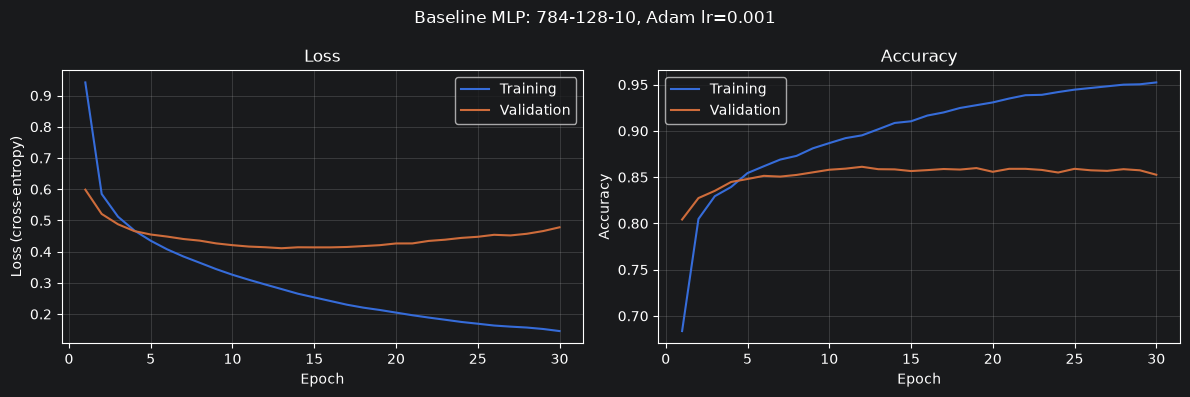

Baseline MLP (training)
  accuracy        = 0.950
  macro precision = 0.951
  macro recall    = 0.950
  macro F1        = 0.950
Baseline MLP (validation)
  accuracy        = 0.853
  macro precision = 0.854
  macro recall    = 0.853
  macro F1        = 0.852


In [8]:
baseline = build_mlp(hidden_units=[128])
baseline.summary()

history_baseline = train(baseline, learning_rate=0.001, epochs=30, batch_size=64)

plot_history(history_baseline, "Baseline MLP: 784-128-10, Adam lr=0.001", "01_baseline.png")
report("Baseline MLP (training)",   y_train, predict_classes(baseline, X_train))
report("Baseline MLP (validation)", y_val,   predict_classes(baseline, X_val))

# Overfitting

Parameters: 932362
Epoch 1/100
79/79 - 2s - 27ms/step - accuracy: 0.6992 - loss: 0.8128 - val_accuracy: 0.8114 - val_loss: 0.5279
Epoch 2/100
79/79 - 1s - 9ms/step - accuracy: 0.8108 - loss: 0.5196 - val_accuracy: 0.8430 - val_loss: 0.4584
Epoch 3/100
79/79 - 1s - 8ms/step - accuracy: 0.8416 - loss: 0.4434 - val_accuracy: 0.8536 - val_loss: 0.4288
Epoch 4/100
79/79 - 1s - 9ms/step - accuracy: 0.8512 - loss: 0.3895 - val_accuracy: 0.8512 - val_loss: 0.4327
Epoch 5/100
79/79 - 1s - 8ms/step - accuracy: 0.8618 - loss: 0.3574 - val_accuracy: 0.8424 - val_loss: 0.4524
Epoch 6/100
79/79 - 1s - 8ms/step - accuracy: 0.8810 - loss: 0.3157 - val_accuracy: 0.8476 - val_loss: 0.4333
Epoch 7/100
79/79 - 1s - 8ms/step - accuracy: 0.8818 - loss: 0.3033 - val_accuracy: 0.8388 - val_loss: 0.4752
Epoch 8/100
79/79 - 1s - 8ms/step - accuracy: 0.8866 - loss: 0.2888 - val_accuracy: 0.8368 - val_loss: 0.4853
Epoch 9/100
79/79 - 1s - 8ms/step - accuracy: 0.8976 - loss: 0.2716 - val_accuracy: 0.8214 - val_los

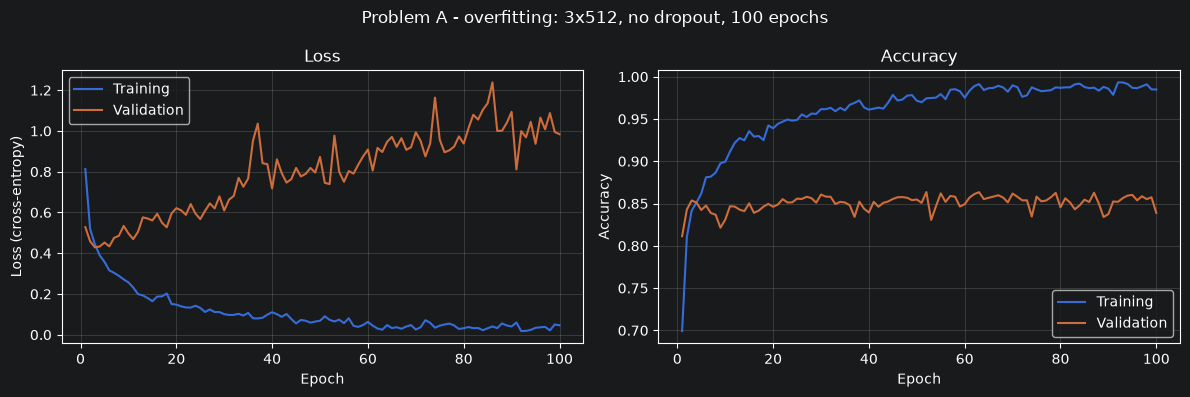

Big model (training)
  accuracy        = 0.977
  macro precision = 0.979
  macro recall    = 0.977
  macro F1        = 0.978
Big model (validation)
  accuracy        = 0.839
  macro precision = 0.847
  macro recall    = 0.839
  macro F1        = 0.841
Lowest validation loss at epoch 3 = 0.429
Validation loss at the last epoch = 0.984


In [9]:
big_model = build_mlp(hidden_units=[512, 512, 512])   # no dropout
print("Parameters:", big_model.count_params())

history_overfit = train(big_model, learning_rate=0.001, epochs=100, batch_size=64)

plot_history(history_overfit, "Problem A - overfitting: 3x512, no dropout, 100 epochs",
             "02_overfitting.png")
report("Big model (training)",   y_train, predict_classes(big_model, X_train))
report("Big model (validation)", y_val,   predict_classes(big_model, X_val))

best_epoch = int(np.argmin(history_overfit.history["val_loss"])) + 1
print("Lowest validation loss at epoch", best_epoch,
      "=", round(min(history_overfit.history["val_loss"]), 3))
print("Validation loss at the last epoch =", round(history_overfit.history["val_loss"][-1], 3))

## Different dropout rate

In [11]:
histories = {0.0: history_overfit}
models = {0.0: big_model}

for rate in [0.2, 0.5, 0.7]:
    print(f"\n========== Dropout {rate} ==========")
    model = build_mlp(hidden_units=[512, 512, 512], dropout=rate)
    histories[rate] = train(model, learning_rate=0.001, epochs=100, batch_size=64)
    models[rate] = model


========== Dropout 0.2 ==========
Epoch 1/100
79/79 - 2s - 28ms/step - accuracy: 0.6596 - loss: 0.9393 - val_accuracy: 0.7898 - val_loss: 0.5636
Epoch 2/100
79/79 - 1s - 9ms/step - accuracy: 0.7784 - loss: 0.6046 - val_accuracy: 0.8286 - val_loss: 0.4944
Epoch 3/100
79/79 - 1s - 9ms/step - accuracy: 0.8040 - loss: 0.5207 - val_accuracy: 0.8342 - val_loss: 0.4659
Epoch 4/100
79/79 - 1s - 9ms/step - accuracy: 0.8324 - loss: 0.4596 - val_accuracy: 0.8440 - val_loss: 0.4347
Epoch 5/100
79/79 - 1s - 9ms/step - accuracy: 0.8440 - loss: 0.4205 - val_accuracy: 0.8386 - val_loss: 0.4496
Epoch 6/100
79/79 - 1s - 9ms/step - accuracy: 0.8522 - loss: 0.3895 - val_accuracy: 0.8492 - val_loss: 0.4182
Epoch 7/100
79/79 - 1s - 8ms/step - accuracy: 0.8502 - loss: 0.3840 - val_accuracy: 0.8520 - val_loss: 0.4058
Epoch 8/100
79/79 - 1s - 8ms/step - accuracy: 0.8658 - loss: 0.3551 - val_accuracy: 0.8516 - val_loss: 0.4135
Epoch 9/100
79/79 - 1s - 9ms/step - accuracy: 0.8678 - loss: 0.3384 - val_accuracy: 

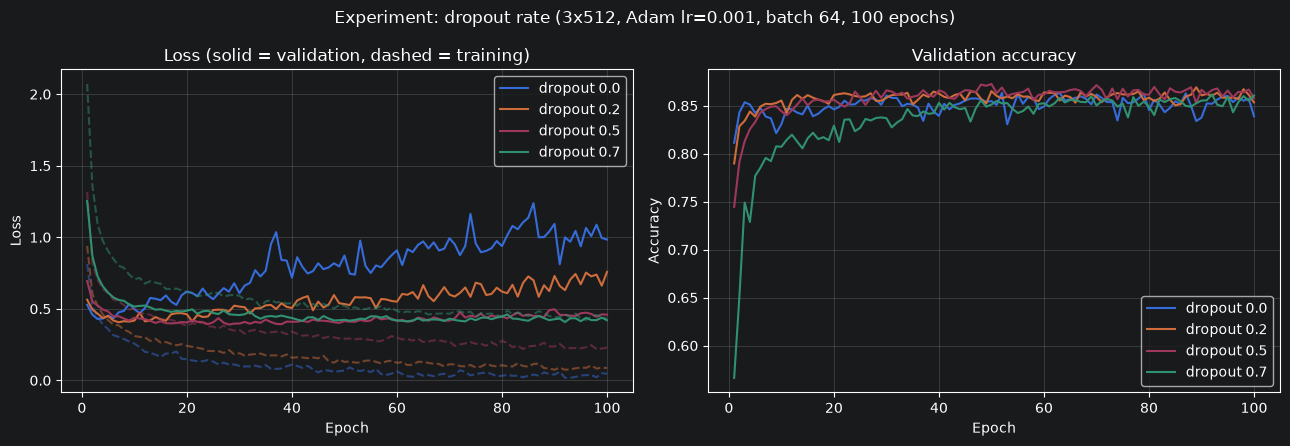

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for rate, h in histories.items():
    epochs = range(1, len(h.history["loss"]) + 1)
    line, = ax1.plot(epochs, h.history["val_loss"], label=f"dropout {rate}")
    ax1.plot(epochs, h.history["loss"], linestyle="--", color=line.get_color(), alpha=0.5)
    ax2.plot(epochs, h.history["val_accuracy"], label=f"dropout {rate}")
ax1.set(xlabel="Epoch", ylabel="Loss", title="Loss (solid = validation, dashed = training)")
ax2.set(xlabel="Epoch", ylabel="Accuracy", title="Validation accuracy")
for v in (ax1, ax2):
    v.grid(alpha=0.3)
    v.legend()
fig.suptitle("Experiment: dropout rate (3x512, Adam lr=0.001, batch 64, 100 epochs)")
plt.tight_layout()
fig.savefig(RESULTS / "03_dropout_experiment.png", dpi=120)
plt.show()

# Unstable training


========== Learning rate 0.01 ==========
Epoch 1/30
79/79 - 1s - 10ms/step - accuracy: 0.6988 - loss: 0.8776 - val_accuracy: 0.8116 - val_loss: 0.5294
Epoch 2/30
79/79 - 0s - 3ms/step - accuracy: 0.8090 - loss: 0.5433 - val_accuracy: 0.8262 - val_loss: 0.4995
Epoch 3/30
79/79 - 0s - 3ms/step - accuracy: 0.8340 - loss: 0.4610 - val_accuracy: 0.8358 - val_loss: 0.4603
Epoch 4/30
79/79 - 0s - 3ms/step - accuracy: 0.8552 - loss: 0.4044 - val_accuracy: 0.8324 - val_loss: 0.4646
Epoch 5/30
79/79 - 0s - 3ms/step - accuracy: 0.8546 - loss: 0.3858 - val_accuracy: 0.8452 - val_loss: 0.4512
Epoch 6/30
79/79 - 0s - 3ms/step - accuracy: 0.8658 - loss: 0.3490 - val_accuracy: 0.8302 - val_loss: 0.4968
Epoch 7/30
79/79 - 0s - 3ms/step - accuracy: 0.8742 - loss: 0.3303 - val_accuracy: 0.8346 - val_loss: 0.5118
Epoch 8/30
79/79 - 0s - 3ms/step - accuracy: 0.8770 - loss: 0.3203 - val_accuracy: 0.8416 - val_loss: 0.4989
Epoch 9/30
79/79 - 0s - 3ms/step - accuracy: 0.8864 - loss: 0.2941 - val_accuracy: 0.

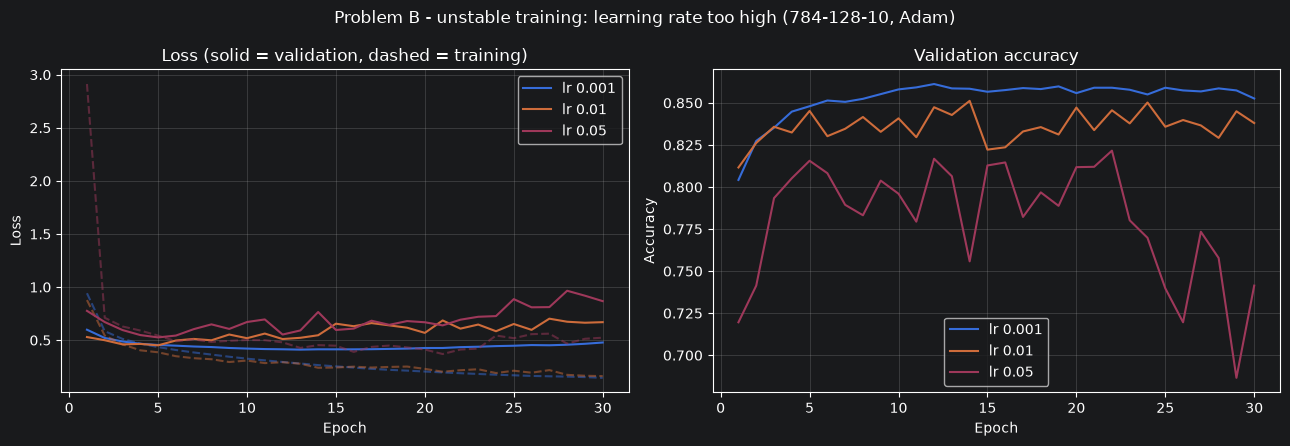

In [13]:
lr_histories = {0.001: history_baseline}

for lr in [0.01, 0.05]:
    print(f"\n========== Learning rate {lr} ==========")
    model = build_mlp(hidden_units=[128])
    lr_histories[lr] = train(model, learning_rate=lr, epochs=30, batch_size=64)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for lr, h in lr_histories.items():
    epochs = range(1, len(h.history["loss"]) + 1)
    line, = ax1.plot(epochs, h.history["val_loss"], label=f"lr {lr}")
    ax1.plot(epochs, h.history["loss"], linestyle="--", color=line.get_color(), alpha=0.5)
    ax2.plot(epochs, h.history["val_accuracy"], label=f"lr {lr}")
ax1.set(xlabel="Epoch", ylabel="Loss", title="Loss (solid = validation, dashed = training)")
ax2.set(xlabel="Epoch", ylabel="Accuracy", title="Validation accuracy")
for v in (ax1, ax2):
    v.grid(alpha=0.3)
    v.legend()
fig.suptitle("Problem B - unstable training: learning rate too high (784-128-10, Adam)")
plt.tight_layout()
fig.savefig(RESULTS / "04_unstable_lr.png", dpi=120)
plt.show()

## Reducing learning rate

Epoch 1/30
79/79 - 1s - 10ms/step - accuracy: 0.5742 - loss: 2.9123 - val_accuracy: 0.7196 - val_loss: 0.7762 - learning_rate: 0.0500
Epoch 2/30
79/79 - 0s - 3ms/step - accuracy: 0.7490 - loss: 0.7109 - val_accuracy: 0.7414 - val_loss: 0.6707 - learning_rate: 0.0500
Epoch 3/30
79/79 - 0s - 3ms/step - accuracy: 0.7760 - loss: 0.6291 - val_accuracy: 0.7934 - val_loss: 0.5952 - learning_rate: 0.0500
Epoch 4/30
79/79 - 0s - 3ms/step - accuracy: 0.7894 - loss: 0.5905 - val_accuracy: 0.8052 - val_loss: 0.5480 - learning_rate: 0.0500
Epoch 5/30
79/79 - 0s - 3ms/step - accuracy: 0.7998 - loss: 0.5431 - val_accuracy: 0.8156 - val_loss: 0.5260 - learning_rate: 0.0500
Epoch 6/30
79/79 - 0s - 3ms/step - accuracy: 0.8234 - loss: 0.4895 - val_accuracy: 0.8082 - val_loss: 0.5433 - learning_rate: 0.0500
Epoch 7/30

Epoch 7: ReduceLROnPlateau reducing learning rate to 0.02500000037252903.
79/79 - 0s - 3ms/step - accuracy: 0.8144 - loss: 0.5073 - val_accuracy: 0.7894 - val_loss: 0.6036 - learning_rate: 

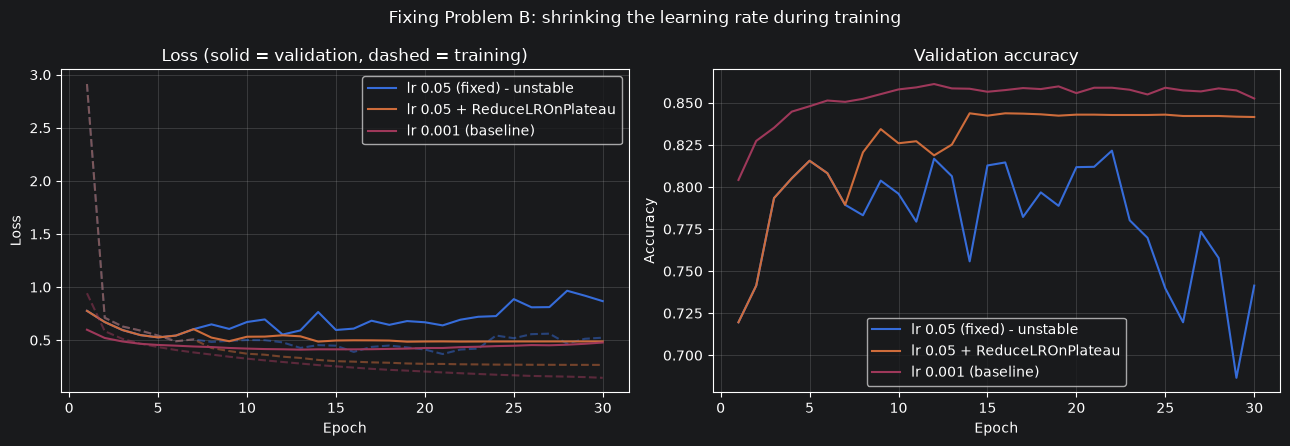

lr 0.05 (fixed) - unstable       best val loss = 0.526 | last val acc = 0.741
lr 0.05 + ReduceLROnPlateau      best val loss = 0.486 | last val acc = 0.842
lr 0.001 (baseline)              best val loss = 0.411 | last val acc = 0.853


In [14]:
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1,
)

model = build_mlp(hidden_units=[128])
history_lr_fixed = train(model, learning_rate=0.05, epochs=30, batch_size=64,
                         callbacks=[reduce_lr])

compare = {
    "lr 0.05 (fixed) - unstable": lr_histories[0.05],
    "lr 0.05 + ReduceLROnPlateau": history_lr_fixed,
    "lr 0.001 (baseline)": lr_histories[0.001],
}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for name, h in compare.items():
    epochs = range(1, len(h.history["loss"]) + 1)
    line, = ax1.plot(epochs, h.history["val_loss"], label=name)
    ax1.plot(epochs, h.history["loss"], linestyle="--", color=line.get_color(), alpha=0.5)
    ax2.plot(epochs, h.history["val_accuracy"], label=name)
ax1.set(xlabel="Epoch", ylabel="Loss", title="Loss (solid = validation, dashed = training)")
ax2.set(xlabel="Epoch", ylabel="Accuracy", title="Validation accuracy")

for v in (ax1, ax2):
    v.grid(alpha=0.3)
    v.legend()
fig.suptitle("Fixing Problem B: shrinking the learning rate during training")
fig.tight_layout()
fig.savefig(RESULTS / "05_unstable_fixed.png", dpi=120)
plt.show()

for name, h in compare.items():
    print(f"{name:32s} best val loss = {min(h.history['val_loss']):.3f} | "
          f"last val acc = {h.history['val_accuracy'][-1]:.3f}")

# Underfitting

Epoch 1/30
79/79 - 1s - 9ms/step - accuracy: 0.2104 - loss: 2.1342 - val_accuracy: 0.2720 - val_loss: 2.0085
Epoch 2/30
79/79 - 0s - 2ms/step - accuracy: 0.3018 - loss: 1.9481 - val_accuracy: 0.3134 - val_loss: 1.8787
Epoch 3/30
79/79 - 0s - 2ms/step - accuracy: 0.3278 - loss: 1.8448 - val_accuracy: 0.3344 - val_loss: 1.7929
Epoch 4/30
79/79 - 0s - 2ms/step - accuracy: 0.3448 - loss: 1.7724 - val_accuracy: 0.3478 - val_loss: 1.7296
Epoch 5/30
79/79 - 0s - 2ms/step - accuracy: 0.3552 - loss: 1.7161 - val_accuracy: 0.3568 - val_loss: 1.6777
Epoch 6/30
79/79 - 0s - 2ms/step - accuracy: 0.3632 - loss: 1.6684 - val_accuracy: 0.3672 - val_loss: 1.6319
Epoch 7/30
79/79 - 0s - 2ms/step - accuracy: 0.4070 - loss: 1.6231 - val_accuracy: 0.4256 - val_loss: 1.5857
Epoch 8/30
79/79 - 0s - 2ms/step - accuracy: 0.4294 - loss: 1.5731 - val_accuracy: 0.4220 - val_loss: 1.5306
Epoch 9/30
79/79 - 0s - 2ms/step - accuracy: 0.4392 - loss: 1.5155 - val_accuracy: 0.4556 - val_loss: 1.4711
Epoch 10/30
79/79 -

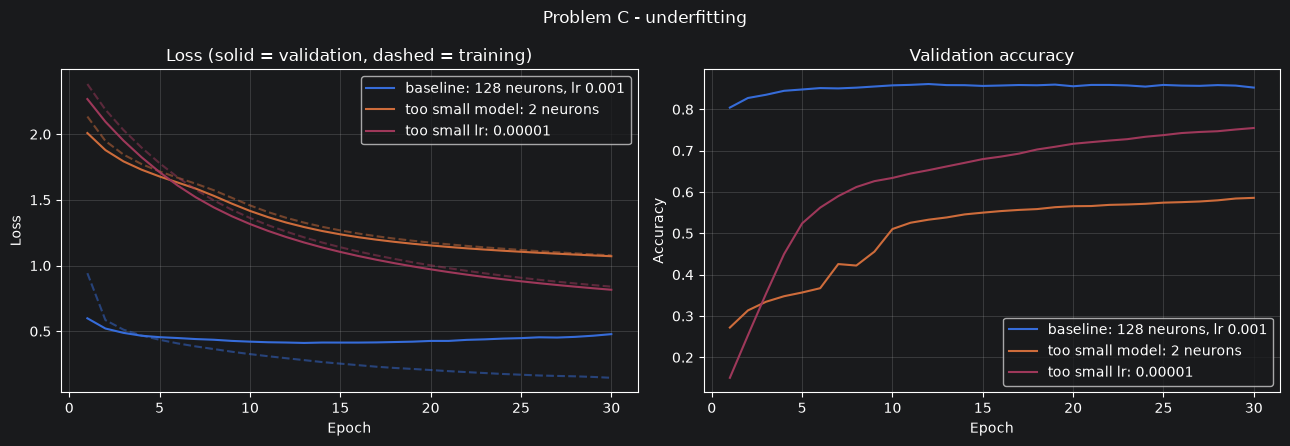

baseline: 128 neurons, lr 0.001     train loss = 0.145 | val loss = 0.478 | val acc = 0.853
too small model: 2 neurons          train loss = 1.077 | val loss = 1.071 | val acc = 0.586
too small lr: 0.00001               train loss = 0.840 | val loss = 0.816 | val acc = 0.755


In [15]:
under = {"baseline: 128 neurons, lr 0.001": history_baseline}

model = build_mlp(hidden_units=[2])
under["too small model: 2 neurons"] = train(model, learning_rate=0.001, epochs=30)

model = build_mlp(hidden_units=[128])
under["too small lr: 0.00001"] = train(model, learning_rate=0.00001, epochs=30)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for name, h in under.items():
    epochs = range(1, len(h.history["loss"]) + 1)
    line, = ax1.plot(epochs, h.history["val_loss"], label=name)
    ax1.plot(epochs, h.history["loss"], linestyle="--", color=line.get_color(), alpha=0.5)
    ax2.plot(epochs, h.history["val_accuracy"], label=name)
ax1.set(xlabel="Epoch", ylabel="Loss", title="Loss (solid = validation, dashed = training)")
ax2.set(xlabel="Epoch", ylabel="Accuracy", title="Validation accuracy")
for v in (ax1, ax2):
    v.grid(alpha=0.3)
    v.legend()
fig.suptitle("Problem C - underfitting")
plt.tight_layout()
fig.savefig(RESULTS / "06_underfitting.png", dpi=120)
plt.show()

for name, h in under.items():
    print(f"{name:35s} train loss = {h.history['loss'][-1]:.3f} | "
          f"val loss = {h.history['val_loss'][-1]:.3f} | "
          f"val acc = {h.history['val_accuracy'][-1]:.3f}")

Epoch 1/100
79/79 - 2s - 21ms/step - accuracy: 0.5160 - loss: 1.3170 - val_accuracy: 0.7446 - val_loss: 0.6940
Epoch 2/100
79/79 - 1s - 8ms/step - accuracy: 0.6972 - loss: 0.8172 - val_accuracy: 0.7916 - val_loss: 0.5515
Epoch 3/100
79/79 - 1s - 8ms/step - accuracy: 0.7354 - loss: 0.7016 - val_accuracy: 0.8130 - val_loss: 0.5221
Epoch 4/100
79/79 - 1s - 9ms/step - accuracy: 0.7748 - loss: 0.6372 - val_accuracy: 0.8256 - val_loss: 0.4945
Epoch 5/100
79/79 - 1s - 8ms/step - accuracy: 0.7830 - loss: 0.6095 - val_accuracy: 0.8330 - val_loss: 0.4807
Epoch 6/100
79/79 - 1s - 8ms/step - accuracy: 0.7944 - loss: 0.5649 - val_accuracy: 0.8428 - val_loss: 0.4469
Epoch 7/100
79/79 - 1s - 8ms/step - accuracy: 0.8032 - loss: 0.5510 - val_accuracy: 0.8464 - val_loss: 0.4481
Epoch 8/100
79/79 - 1s - 9ms/step - accuracy: 0.8152 - loss: 0.5255 - val_accuracy: 0.8490 - val_loss: 0.4320
Epoch 9/100
79/79 - 1s - 8ms/step - accuracy: 0.8202 - loss: 0.4952 - val_accuracy: 0.8494 - val_loss: 0.4180
Epoch 10/

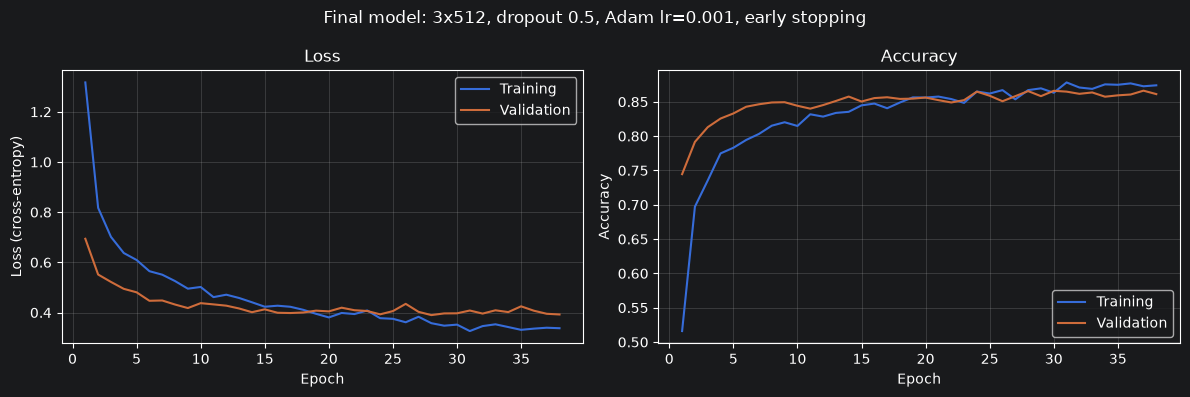

Trained for 38 epochs; best (kept) epoch = 28 ; best val loss = 0.39
Final model (training)
  accuracy        = 0.910
  macro precision = 0.910
  macro recall    = 0.910
  macro F1        = 0.909
Final model (validation)
  accuracy        = 0.866
  macro precision = 0.865
  macro recall    = 0.866
  macro F1        = 0.864


In [16]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1,
)

final_model = build_mlp(hidden_units=[512, 512, 512], dropout=0.5)
history_final = train(final_model, learning_rate=0.001, epochs=100, batch_size=64,
                      callbacks=[early_stop])

plot_history(history_final, "Final model: 3x512, dropout 0.5, Adam lr=0.001, early stopping",
             "07_final_model.png")

best = int(np.argmin(history_final.history["val_loss"])) + 1
print("Trained for", len(history_final.history["loss"]), "epochs; best (kept) epoch =", best,
      "; best val loss =", round(min(history_final.history["val_loss"]), 3))
report("Final model (training)",   y_train, predict_classes(final_model, X_train))
report("Final model (validation)", y_val,   predict_classes(final_model, X_val))

FINAL MODEL - TEST SET
  accuracy        = 0.846
  macro precision = 0.846
  macro recall    = 0.846
  macro F1        = 0.845
Baseline MLP - test set (reference only)
  accuracy        = 0.837
  macro precision = 0.839
  macro recall    = 0.837
  macro F1        = 0.836

Per-class results of the final model (test set):
              precision    recall  f1-score   support

 T-shirt/top      0.812     0.779     0.795      1000
     Trouser      0.986     0.945     0.965      1000
    Pullover      0.722     0.773     0.746      1000
       Dress      0.787     0.919     0.848      1000
        Coat      0.755     0.701     0.727      1000
      Sandal      0.975     0.905     0.939      1000
       Shirt      0.649     0.580     0.613      1000
     Sneaker      0.905     0.952     0.928      1000
         Bag      0.937     0.961     0.949      1000
  Ankle boot      0.928     0.944     0.936      1000

    accuracy                          0.846     10000
   macro avg      0.846     

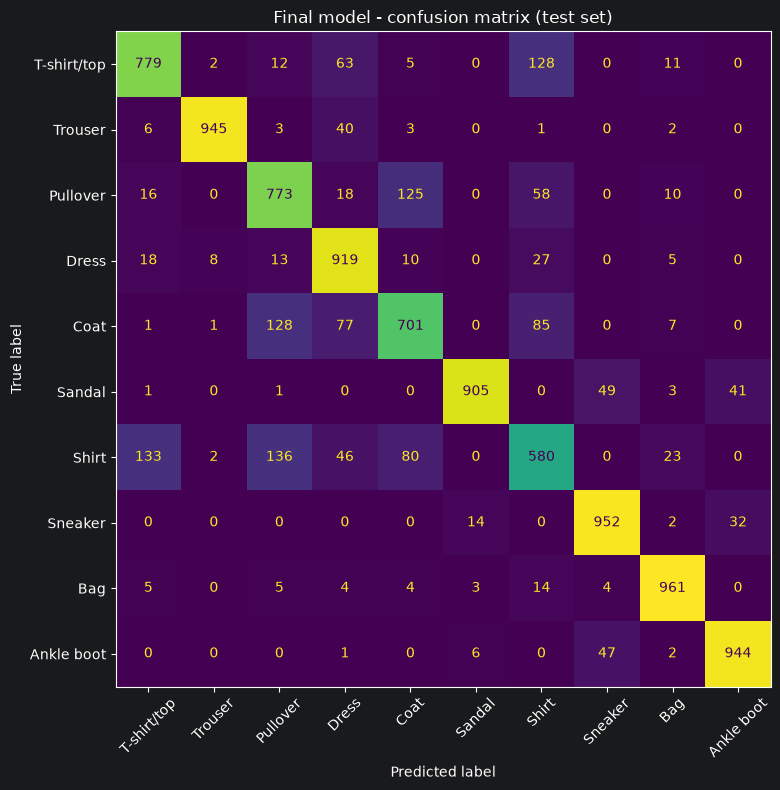

In [17]:
y_test_pred = predict_classes(final_model, X_test)
report("FINAL MODEL - TEST SET", y_test, y_test_pred)
report("Baseline MLP - test set (reference only)", y_test, predict_classes(baseline, X_test))

print("\nPer-class results of the final model (test set):")
print(classification_report(y_test, y_test_pred, target_names=CLASS_NAMES, digits=3))

fig, v = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred, display_labels=CLASS_NAMES,
    xticks_rotation=45, ax=v, colorbar=False,
)
v.set_title("Final model - confusion matrix (test set)")
plt.tight_layout()
fig.savefig(RESULTS / "08_confusion_matrix.png", dpi=120)
plt.show()